In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.base import clone

SEED = 42

In [9]:
categories = [
    "comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "talk.politics.misc",
]

clean = ("headers", "footers", "quotes")

dev = fetch_20newsgroups(
    subset="train", categories=categories, remove=clean, shuffle=True, random_state=SEED
)

print(dev.target_names)
print(len(dev.data))

label_counts = pd.Series(dev.target).value_counts().sort_index()
display(pd.DataFrame({
    "category": dev.target_names,
    "documents": label_counts.values,
}))

print(dev.data[0][:900])

['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']
2239


,category,documents
0,comp.graphics,584
1,rec.sport.baseball,597
2,sci.space,593
3,talk.politics.misc,465


I thought that was Sandy Koufax.


In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    dev.data, dev.target, test_size=0.2, random_state=SEED, stratify=dev.target
)

In [11]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

pred_dummy = dummy.predict(X_val)

def metrics_row(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }

results = [metrics_row("Dummy", y_val, pred_dummy)]
display(pd.DataFrame(results))

,model,accuracy,macro_f1
0,Dummy,0.265625,0.104938


In [12]:
text_clf = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

text_clf.fit(X_train, y_train)
pred_tfidf = text_clf.predict(X_val)

results.append(metrics_row("TF-IDF + LogisticRegression", y_val, pred_tfidf))
results_df = pd.DataFrame(results)
display(results_df.style.format({"accuracy": "{:.4f}", "macro_f1": "{:.4f}"}))

print(classification_report(
    y_val,
    pred_tfidf,
    target_names=dev.target_names,
    zero_division=0,
))

,model,accuracy,macro_f1
0,Dummy,0.2656,0.1049
1,TF-IDF + LogisticRegression,0.8772,0.8754


                    precision    recall  f1-score   support

     comp.graphics       0.87      0.89      0.88       117
rec.sport.baseball       0.85      0.95      0.90       119
         sci.space       0.88      0.86      0.87       119
talk.politics.misc       0.93      0.80      0.86        93

          accuracy                           0.88       448
         macro avg       0.88      0.87      0.88       448
      weighted avg       0.88      0.88      0.88       448



In [13]:
vec = text_clf.named_steps["tfidf"]
X_train_sparse = vec.transform(X_train)

n_docs, n_features = X_train_sparse.shape
non_zero = X_train_sparse.nnz
density = non_zero / (n_docs * n_features)

print("Sparse matrix shape:", X_train_sparse.shape)
print("Number of vocabulary terms:", len(vec.vocabulary_))
print("Nonzero entries:", non_zero)
print(f"Density: {density:.4%}")
print("First 20 vocabulary terms:", vec.get_feature_names_out()[:20])

vocab_before = len(vec.vocabulary_)
_ = vec.transform(X_val)
assert len(vec.vocabulary_) == vocab_before

Sparse matrix shape: (1791, 24380)
Number of vocabulary terms: 24380
Nonzero entries: 168701
Density: 0.3864%
First 20 vocabulary terms: ['00' '000' '0000' '00000' '000000' '000005102000' '000062david42'
 '00041032' '0004246' '0004422' '00044513' '0004847546' '0005' '0007'
 '000k' '000th' '000usd' '0012' '0018' '00196']


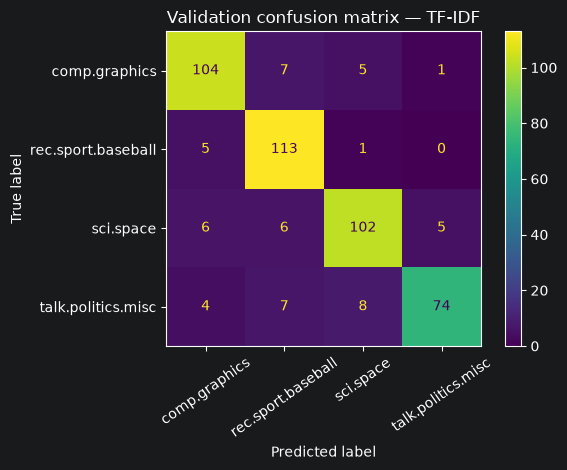

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    pred_tfidf,
    display_labels=dev.target_names,
    xticks_rotation=35,
)
plt.title("Validation confusion matrix — TF-IDF")
plt.tight_layout()
plt.show()

In [15]:
wrong_positions = np.flatnonzero(np.asarray(y_val) != pred_tfidf)
selected = wrong_positions[:10]

errors_df = pd.DataFrame({
    "val_index": selected,
    "true_category": [dev.target_names[y_val[i]] for i in selected],
    "predicted_category": [dev.target_names[pred_tfidf[i]] for i in selected],
    "text_excerpt": [X_val[i].replace("\n", " ")[:350] for i in selected],
})

print(len(wrong_positions))
print(len(errors_df))
display(errors_df)

for i in selected:
    print("\n" + "=" * 72)
    print(f"VAL index {i}: true={dev.target_names[y_val[i]]}; predicted={dev.target_names[pred_tfidf[i]]}")
    print(X_val[i][:1500])

55
10


,val_index,true_category,predicted_category,text_excerpt
0,7,comp.graphics,sci.space,"SAMPE, NCGA, The University of Akron, and NASA..."
1,15,rec.sport.baseball,comp.graphics,No one says you have to read any of it ...
2,18,talk.politics.misc,sci.space,*Teddy O'Neill-Creature with furry Hobbit feet...
3,22,sci.space,talk.politics.misc,"\tOk, so how about the creation of oil produc..."
4,32,rec.sport.baseball,comp.graphics,"yup. with onions, of all things."
5,35,rec.sport.baseball,comp.graphics,I am trying to get a copy of the _official_ ru...
6,47,talk.politics.misc,sci.space,\tMy understanding from my psycology classes ...
7,51,rec.sport.baseball,comp.graphics,"I agree, although I would have no idea how t..."
8,54,sci.space,talk.politics.misc,\tThey did the rollout already??!? I am go...
9,71,comp.graphics,rec.sport.baseball,



VAL index 7: true=comp.graphics; predicted=sci.space
SAMPE, NCGA, The University of Akron, and NASA Lewis Research Center
is sponsoring:

                      COMPUTERS AND COMPOSITES

	A one-day seminar devoted to practical applications of
	computer workstations for efficient processing, design, and
			Manufacture of composites

May 18, 1993
at
 The University of Akron
  Akron, Ohio

Speakers on:
 Advancement in Graphics Visualization   Dr. Jay Horowitz, NASA
 Integrated Product Development with     Mr. Michael R. Cowen
  Network Workstations		          Sikorski Aircraft
 Structural Analysis			 Mr. Brian Fite, NASA
 Stereolithography			 Mr. Jason Williams, Penn State-Erie
 Molecular and Physical Modeling	 Dr. Vassilios Galiatsato,
  of Polymer Curing                       University of Akron
 Process Modeling of Polymer
  Matrix Composites			 Dr Ram Upadhyay, GE Corporate R&D

Registration Fees: $75.00 Advance, $100.00 on site (Includes box lunch)

Contact Gary Roberts, NASA Lewis R

In [16]:
final_model = clone(text_clf)
final_model.fit(dev.data, dev.target)

official_test = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=clean,
    shuffle=True,
    random_state=SEED,
)

pred_test = final_model.predict(official_test.data)
print("Official test (single final evaluation):")
print("Accuracy:", round(accuracy_score(official_test.target, pred_test), 4))
print("Macro-F1:", round(f1_score(official_test.target, pred_test, average="macro"), 4))

Official test (single final evaluation):
Accuracy: 0.8409
Macro-F1: 0.838
